# Sonar contact detection with Qwen3-VL: test evaluation

I evaluate the saved QLoRA adapter on spatially held-out sonar patches. The checkpoint was selected by the lowest validation loss at epoch 3.

The default test subset contains 125 annotated images and 167 boxes. Unreviewed empty-label images are excluded. Predictions, detection metrics and visual examples are saved below.


## Configuration

Set the training-run and dataset paths. `SPLIT='test'` and `MAX_IMAGES=None` evaluate all eligible test patches.


In [1]:
from pathlib import Path
import json,time,random,math,hashlib,shutil,csv,subprocess,sys,gc
from datetime import datetime,timezone
MYDRIVE=Path('/content/drive/MyDrive')
SOURCE_RUN=MYDRIVE/'LLM-fine-tuning/Qwen3-VL-4B-contact/epochs_v3_20261016T100839_368773Z'
ADAPTER_DIR=SOURCE_RUN/'adapter_best'
DATA_ZIP=MYDRIVE/'sss_contact_yolo26_spatial_split_A_round2_v001.zip'
OUTPUT_ROOT=MYDRIVE/'LLM-fine-tuning/Qwen3-VL-4B-contact'
SPLIT='test'
MAX_IMAGES=None
MAX_NEW_TOKENS=512
MATCH_IOU=0.5
EXAMPLES_PER_CATEGORY=6
REVIEWED_NEGATIVES_CSV=None
AUTO_DISCONNECT=False
SEED=42
assert SPLIT in {'val','test'}
assert MAX_IMAGES is None or (isinstance(MAX_IMAGES,int) and MAX_IMAGES>0)


## Dependencies

Use the same core library versions as the training notebook. Installed versions are recorded with the results.


In [2]:
assert sys.version_info>=(3,10)
subprocess.check_call([sys.executable,'-m','pip','install','-q',
    'transformers==4.57.6','peft==0.18.1','accelerate==1.15.0',
    'bitsandbytes==0.49.2','huggingface_hub==0.36.2','matplotlib','scipy','pandas','Pillow'])


0

## Checkpoint verification

Read the saved training records and verify that `adapter_best` matches the epoch with the lowest validation loss. No weights are updated during evaluation.


In [3]:
from google.colab import drive
drive.mount('/content/drive')
import torch
assert torch.cuda.is_available(),'A CUDA GPU is required.'
print(subprocess.getoutput('nvidia-smi'))
assert (SOURCE_RUN/'config.json').is_file(),f'Training config not found: {SOURCE_RUN}'
assert (ADAPTER_DIR/'adapter_config.json').is_file(),f'Adapter config not found: {ADAPTER_DIR}'
assert (ADAPTER_DIR/'adapter_model.safetensors').is_file(),f'Adapter weights not found: {ADAPTER_DIR}'
saved_config=json.loads((SOURCE_RUN/'config.json').read_text())
adapter_config=json.loads((ADAPTER_DIR/'adapter_config.json').read_text())
MODEL_ID=saved_config['MODEL_ID'];MODEL_REVISION=saved_config['MODEL_REVISION']
PROMPT=saved_config['PROMPT']
assert MODEL_ID=='Qwen/Qwen3-VL-4B-Instruct'
assert adapter_config['base_model_name_or_path']==MODEL_ID
assert adapter_config['peft_type']=='LORA'
assert (ADAPTER_DIR/'preprocessor_config.json').is_file()
STAMP=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN=OUTPUT_ROOT/('inference_'+SPLIT+'_'+STAMP)
RUN.mkdir(parents=True,exist_ok=False)
def save_json(name,obj):
    target=RUN/name;target.parent.mkdir(parents=True,exist_ok=True)
    temp=target.with_name(target.name+'.tmp')
    temp.write_text(json.dumps(obj,indent=2,allow_nan=False));temp.replace(target)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
# Verify checkpoint selection from saved training records before test inference.
summary_path=SOURCE_RUN/'training_summary.json'
history_path=SOURCE_RUN/'loss_history.json'
assert summary_path.is_file() and history_path.is_file(), 'Training summary/history required.'
training_summary=json.loads(summary_path.read_text())
loss_history=json.loads(history_path.read_text())
completed=[h for h in loss_history if h['epoch']>0]
assert completed and all(math.isfinite(h['val_loss']) for h in completed)
winning=min(completed,key=lambda h:h['val_loss'])
best_epoch=int(training_summary['best_epoch'])
assert best_epoch==winning['epoch'], 'Summary best epoch disagrees with loss history.'
assert math.isclose(training_summary['best_val_loss'],winning['val_loss'],rel_tol=1e-9)
assert training_summary['completed_epochs']==len(completed)==saved_config['EPOCHS'], 'Expected a fully completed training run.'
winning_weights=SOURCE_RUN/f'adapter_epoch_{best_epoch:02d}'/'adapter_model.safetensors'
assert winning_weights.is_file(), f'Winning epoch weights not found: {winning_weights}'
assert sha256_file(ADAPTER_DIR/'adapter_model.safetensors')==sha256_file(winning_weights), 'adapter_best differs from selected epoch weights.'
checkpoint_selection={'criterion':'minimum_validation_loss','best_epoch':best_epoch,
    'best_val_loss':winning['val_loss'],'winning_epoch_weights':str(winning_weights),
    'summary_sha256':sha256_file(summary_path),'history_sha256':sha256_file(history_path)}
print('Verified checkpoint selection:',json.dumps(checkpoint_selection,indent=2))

config={'model':MODEL_ID,'revision':MODEL_REVISION,'adapter':str(ADAPTER_DIR),
    'adapter_sha256':sha256_file(ADAPTER_DIR/'adapter_model.safetensors'),
    'data_zip':str(DATA_ZIP),'split':SPLIT,'max_images':MAX_IMAGES,
    'max_new_tokens':MAX_NEW_TOKENS,'match_iou':MATCH_IOU,'seed':SEED,'prompt':PROMPT,
    'training':False,'test_used_for_selection':False,
    'checkpoint_selection':checkpoint_selection}
save_json('inference_config.json',config)
save_json('resource_start.json',{'gpu':subprocess.getoutput('nvidia-smi'),'utc':datetime.now(timezone.utc).isoformat()})
print('Adapter:',ADAPTER_DIR,'bytes:',(ADAPTER_DIR/'adapter_model.safetensors').stat().st_size)
print('Results:',RUN)


Mounted at /content/drive
Sat Oct 17 13:08:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   45C    P8             14W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

## Evaluation data

Load the spatial test split, check label hashes and spatial separation, and exclude unreviewed empty labels. Counts refer to patch-level annotations; overlapping patches may repeat targets.


In [4]:
import zipfile
import numpy as np
from PIL import Image

def safe_extract(archive,destination):
    destination=Path(destination); destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            name=item.filename
            if name.startswith('/') or '..' in Path(name).parts or '\\' in name:
                raise ValueError('Unsafe archive member: '+name)
            if (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError('Archive symlink disallowed: '+name)
        assert z.testzip() is None, 'ZIP integrity check failed'
        z.extractall(destination)

def load_dataset(root,reviewed_negatives=None):
    root=Path(root); reviewed_negatives=reviewed_negatives or set()
    full=list(root.rglob('split_manifest_A_round2_v001.csv'))
    result=[]; skipped={s:0 for s in ['train','val','test','buffer']}
    if full:
        assert len(full)==1,'Multiple dataset manifests'
        bundle=full[0].parent.parent
        for r in csv.DictReader(full[0].open()):
            split=r['final_split']; pid=r['patch_id']
            if split=='buffer':skipped[split]+=1;continue
            label=bundle/'data'/'labels'/split/(pid+'.txt')
            image=bundle/'data'/'images'/split/(pid+'.png')
            assert image.is_file() and label.is_file(),pid
            raw=label.read_bytes()
            if r.get('label_sha256'):
                assert hashlib.sha256(raw).hexdigest()==r['label_sha256'],pid+' label hash mismatch'
            boxes=[]
            for line in raw.decode().splitlines():
                if not line.strip():continue
                c,x,y,w,h=map(float,line.split())
                assert c==0 and w>0 and h>0 and all(math.isfinite(v) for v in [x,y,w,h])
                box=[round(1000*max(0,x-w/2)),round(1000*max(0,y-h/2)),
                     round(1000*min(1,x+w/2)),round(1000*min(1,y+h/2))]
                assert 0<=box[0]<box[2]<=1000 and 0<=box[1]<box[3]<=1000,(pid,box)
                boxes.append(box)
            approved=(pid,split) in reviewed_negatives
            if not boxes and not approved:skipped[split]+=1;continue
            result.append({'patch_id':pid,'split':split,'image':str(image),
                'boxes_1000':sorted(boxes,key=lambda b:(b[1],b[0])),
                'negative_reviewed':bool(approved and not boxes),'label_source':r['label_source'],
                'spatial_chunk':int(r['spatial_chunk']),
                'footprint':[float(r[k]) for k in ['x0','y0','x1','y1']]})
        mode='full_round2_bundle'
    else:
        candidates=list(root.rglob('manifest.json'))
        assert len(candidates)==1,'No supported full/pilot manifest found'
        bundle=candidates[0].parent
        for r in json.loads(candidates[0].read_text()):
            split=r['final_split'];pid=r['patch_id'];image=bundle/r['image']
            assert hashlib.sha256(image.read_bytes()).hexdigest()==r['image_sha256'],pid
            approved=(pid,split) in reviewed_negatives
            if not r['boxes_1000'] and not approved:skipped[split]+=1;continue
            result.append({'patch_id':pid,'split':split,'image':str(image),
                'boxes_1000':r['boxes_1000'],'negative_reviewed':bool(approved and not r['boxes_1000']),
                'label_source':r['label_source'],'spatial_chunk':int(r['spatial_chunk']),
                'footprint':[float(r[k]) for k in ['x0','y0','x1','y1']]})
        mode='64_image_pilot_ONLY'
    keys=[(r['split'],r['patch_id']) for r in result]
    assert len(keys)==len(set(keys)),'Duplicate records'
    return result,mode,skipped

def subsample(rows,limit,seed):
    rows=sorted(rows,key=lambda r:r['patch_id'])
    if limit is None or limit>=len(rows):return rows
    assert limit>0

    groups={}
    for r in rows:groups.setdefault(min(len(r['boxes_1000']),2),[]).append(r)
    rng=random.Random(seed)
    for group in groups.values():rng.shuffle(group)
    picked=[]
    while len(picked)<limit:
        for key in sorted(groups):
            if groups[key] and len(picked)<limit:picked.append(groups[key].pop())
    return sorted(picked,key=lambda r:r['patch_id'])

def minimum_gap(a,b):
    assert a and b
    bb=np.asarray([r['footprint'] for r in b]);answer=float('inf')
    for start in range(0,len(a),128):
        aa=np.asarray([r['footprint'] for r in a[start:start+128]])
        dx=np.maximum(0,np.maximum(aa[:,None,0]-bb[None,:,2],bb[None,:,0]-aa[:,None,2]))
        dy=np.maximum(0,np.maximum(aa[:,None,1]-bb[None,:,3],bb[None,:,1]-aa[:,None,3]))
        answer=min(answer,float(np.sqrt(dx*dx+dy*dy).min()))
    return answer


In [5]:
if not DATA_ZIP.is_file():
    found=list(MYDRIVE.rglob(DATA_ZIP.name))
    assert len(found)==1,'Set DATA_ZIP to the full round-2 dataset archive.'
    DATA_ZIP=found[0]
DATA=Path('/content/sss_contact_inference')/STAMP
safe_extract(DATA_ZIP,DATA)
reviewed=set()
if REVIEWED_NEGATIVES_CSV is not None:
    with Path(REVIEWED_NEGATIVES_CSV).open() as f:
        reviewed={(r['patch_id'],r['split']) for r in csv.DictReader(f)}
all_rows,DATA_MODE,excluded=load_dataset(DATA,reviewed)
assert DATA_MODE=='full_round2_bundle','The full round-2 dataset is required.'
rows=subsample([r for r in all_rows if r['split']==SPLIT],MAX_IMAGES,SEED)
assert rows,'No evaluation images found.'
train_rows=[r for r in all_rows if r['split']=='train']
gap=minimum_gap(train_rows,rows)
assert gap>=15-1e-6,('Spatial gap below 15 m',gap)
if SPLIT=='test':
    validation_rows=[r for r in all_rows if r['split']=='val']
    validation_test_gap=minimum_gap(validation_rows,rows)
    assert validation_test_gap>=15-1e-6, ('Validation/test spatial gap below 15 m',validation_test_gap)
assert all(r['spatial_chunk'] in ({8,9} if SPLIT=='val' else {10,11}) for r in rows)
summary={'mode':DATA_MODE,'split':SPLIT,'images':len(rows),
    'boxes':sum(len(r['boxes_1000']) for r in rows),
    'reviewed_negatives':sum(r['negative_reviewed'] for r in rows),
    'excluded_unreviewed_empty':excluded,'min_train_evaluation_gap_m':gap,
    'partial_run':MAX_IMAGES is not None,'data_zip_sha256':sha256_file(DATA_ZIP)}
save_json('dataset_summary.json',summary);save_json('selected_manifest.json',rows)
print(json.dumps(summary,indent=2))

if not summary['reviewed_negatives']:
    print('Positive-patch subset only: no audited background false-positive rate or TN is available.')


{
  "mode": "full_round2_bundle",
  "split": "test",
  "images": 125,
  "boxes": 167,
  "reviewed_negatives": 0,
  "excluded_unreviewed_empty": {
    "train": 5115,
    "val": 1420,
    "test": 1480,
    "buffer": 608
  },
  "min_train_evaluation_gap_m": 295.0,
  "partial_run": false,
  "data_zip_sha256": "76f992637d2b7177d5bc274b6dbbc4a946c548472ffa3c8cde746ee889fb7757"
}
Positive-patch subset only: no audited background false-positive rate or TN is available.


## Load the model

Load the pinned 4-bit Qwen3-VL base model, saved processor and selected adapter. All parameters remain frozen.


In [6]:
import importlib.metadata as metadata
from transformers import AutoProcessor,Qwen3VLForConditionalGeneration,BitsAndBytesConfig
from peft import PeftModel,prepare_model_for_kbit_training
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
processor=AutoProcessor.from_pretrained(str(ADAPTER_DIR),local_files_only=True)
processor.tokenizer.padding_side='right'
assert processor.image_processor.min_pixels==256*256 and processor.image_processor.max_pixels==256*256, 'Image preprocessing differs from the training experiment.'
base=Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=DTYPE),
    torch_dtype=DTYPE,device_map={'':0},attn_implementation='sdpa')

base=prepare_model_for_kbit_training(base,use_gradient_checkpointing=False)
model=PeftModel.from_pretrained(base,str(ADAPTER_DIR),is_trainable=False)
model.requires_grad_(False);model.eval();model.gradient_checkpointing_disable();model.config.use_cache=True
assert not any(p.requires_grad for p in model.parameters())
lora_parameters=[n for n,p in model.named_parameters() if 'lora_' in n]
assert lora_parameters,'No LoRA parameters were loaded.'
save_json('versions.json',{p:metadata.version(p) for p in ['torch','transformers','peft','accelerate','bitsandbytes','numpy','scipy','Pillow']})
print('Saved adapter loaded. LoRA tensors:',len(lora_parameters),'No trainable parameters.')
torch.cuda.reset_peak_memory_stats()


`torch_dtype` is deprecated! Use `dtype` instead!
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.91G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Saved adapter loaded. LoRA tensors: 288 No trainable parameters.


## Inference and metrics

Generate JSON bounding boxes and match predictions to annotations one-to-one. Report precision, recall and F1 at IoU thresholds of 0.25, 0.50 and 0.75, alongside JSON errors and truncated outputs. No AP/mAP is calculated.


In [7]:
def encode(r,answer=False):
    msg=[{'role':'user','content':[{'type':'image'},{'type':'text','text':PROMPT}]}]
    if answer:msg.append({'role':'assistant','content':json.dumps({'boxes':r['boxes_1000']},separators=(',',':'))})
    text=processor.apply_chat_template(msg,tokenize=False,add_generation_prompt=not answer)
    with Image.open(r['image']) as im:image=im.convert('RGB')
    b=processor(text=[text],images=[image],return_tensors='pt');b.pop('token_type_ids',None)
    if answer:
        prefix=encode(r)['input_ids'];n=prefix.shape[1]
        assert torch.equal(b['input_ids'][:,:n],prefix),'Assistant-prefix masking mismatch'
        b['labels']=b['input_ids'].clone();b['labels'][:,:n]=-100
        assert (b['labels'][:,1:]!=-100).sum()>0
    return b

def parse_boxes(text):
    import re
    try:
        text=text.strip()
        if text.startswith('```'):text=re.sub(r'^```(?:json)?\s*|\s*```$','',text)
        d=json.loads(text)
        if not isinstance(d,dict) or set(d)!={'boxes'} or not isinstance(d['boxes'],list):return [],False
        for b in d['boxes']:
            if not isinstance(b,list) or len(b)!=4:return [],False
            if any(isinstance(v,bool) or not isinstance(v,(int,float)) or not math.isfinite(v) for v in b):return [],False
            if not(0<=b[0]<b[2]<=1000 and 0<=b[1]<b[3]<=1000):return [],False
        return d['boxes'],True
    except (ValueError,TypeError):return [],False

def box_iou(a,b):
    intersection=max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
    union=(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-intersection
    return intersection/union if union>0 else 0.0

def match_boxes(pred,gt,threshold):
    from scipy.optimize import linear_sum_assignment
    pairs=[]
    if pred and gt:
        mat=np.array([[box_iou(p,g) for g in gt] for p in pred])
        score=(mat>=threshold)*(min(len(pred),len(gt))+1)+mat
        ii,jj=linear_sum_assignment(score,maximize=True)
        pairs=[(int(i),int(j),float(mat[i,j])) for i,j in zip(ii,jj) if mat[i,j]>=threshold]
    used_p={p[0] for p in pairs};used_g={p[1] for p in pairs}
    return pairs,[i for i in range(len(pred)) if i not in used_p],[j for j in range(len(gt)) if j not in used_g]

def summarize_detection(predictions,threshold):
    tp=fp=fn=tn=reviewed_empty=invalid=0
    for p in predictions:
        pairs,extra,missed=match_boxes(p['boxes'],p['ground_truth'],threshold)
        tp+=len(pairs);fp+=len(extra);fn+=len(missed);invalid+=not p['valid_json']
        if p['negative_reviewed'] and not p['ground_truth']:
            reviewed_empty+=1
            tn+=int(p['valid_json'] and not p['boxes'] and not p['hit_token_limit'])
    precision=tp/(tp+fp) if tp+fp else 0.0;recall=tp/(tp+fn) if tp+fn else 0.0
    return {'iou':threshold,'tp_boxes':tp,'fp_boxes':fp,'fn_boxes':fn,
        'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.0,
        'tn_images':tn if reviewed_empty else None,'reviewed_negative_images':reviewed_empty,
        'invalid_json_images':invalid,'images':len(predictions),
        'note':'TP/FP/FN are box counts; TN is an image count, not a detection-box TN. Invalid output is never TN.'}

@torch.inference_mode()
def predict(rows,tag):
    model.eval();model.config.use_cache=True;model.gradient_checkpointing_disable()
    predictions=[];started=time.monotonic()
    for i,r in enumerate(rows):
        b={k:v.to('cuda') for k,v in encode(r).items()}
        ids=model.generate(**b,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,use_cache=True)
        tail=ids[:,b['input_ids'].shape[1]:]
        text=processor.batch_decode(tail,skip_special_tokens=True,clean_up_tokenization_spaces=False)[0]
        boxes,valid=parse_boxes(text)
        predictions.append({'patch_id':r['patch_id'],'image':r['image'],'boxes':boxes,
            'ground_truth':r['boxes_1000'],'negative_reviewed':r['negative_reviewed'],
            'valid_json':valid,'raw_text':text,'hit_token_limit':tail.shape[1]>=MAX_NEW_TOKENS})
        if (i+1)%10==0 or i+1==len(rows):
            save_json(tag+'_predictions.json',predictions)
            print(tag,i+1,'/',len(rows),flush=True)
        del b,ids,tail
    metrics=[summarize_detection(predictions,t) for t in [0.25,0.5,0.75]]
    save_json(tag+'_metrics.json',{'metrics':metrics,'seconds':time.monotonic()-started,
        'json_valid_rate':sum(p['valid_json'] for p in predictions)/len(predictions),
        'token_limit_images':sum(p['hit_token_limit'] for p in predictions)})
    return predictions,metrics


In [8]:
tag='saved_adapter_'+SPLIT
predictions,metrics=predict(rows,tag)

table=pd.DataFrame(metrics);display(table)
table.to_csv(RUN/'detection_metrics.csv',index=False)
flat=[]
for p in predictions:
    for i,b in enumerate(p['boxes']):
        flat.append({'patch_id':p['patch_id'],'box_index':i,'x1':b[0],'y1':b[1],
                     'x2':b[2],'y2':b[3],'valid_json':p['valid_json']})
pd.DataFrame(flat,columns=['patch_id','box_index','x1','y1','x2','y2','valid_json']).to_csv(RUN/'predicted_boxes_1000.csv',index=False)
print('Invalid JSON:',sum(not p['valid_json'] for p in predictions))
print('Token limit reached:',sum(p['hit_token_limit'] for p in predictions))


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


saved_adapter_test 10 / 125
saved_adapter_test 20 / 125
saved_adapter_test 30 / 125
saved_adapter_test 40 / 125
saved_adapter_test 50 / 125
saved_adapter_test 60 / 125
saved_adapter_test 70 / 125
saved_adapter_test 80 / 125
saved_adapter_test 90 / 125
saved_adapter_test 100 / 125
saved_adapter_test 110 / 125
saved_adapter_test 120 / 125
saved_adapter_test 125 / 125


,iou,tp_boxes,fp_boxes,fn_boxes,precision,recall,f1,tn_images,reviewed_negative_images,invalid_json_images,images,note
0,0.25,114,49,53,0.699387,0.682635,0.690909,None,0,0,125,"TP/FP/FN are box counts; TN is an image count,..."
1,0.50,87,76,80,0.533742,0.520958,0.527273,None,0,0,125,"TP/FP/FN are box counts; TN is an image count,..."
2,0.75,21,142,146,0.128834,0.125749,0.127273,None,0,0,125,"TP/FP/FN are box counts; TN is an image count,..."


Invalid JSON: 0
Token limit reached: 0


## Detection examples

Solid green: matched prediction; dashed green: matched annotation; red: unmatched prediction; yellow: missed annotation. One image may contain several outcomes. TN requires reviewed negative images.


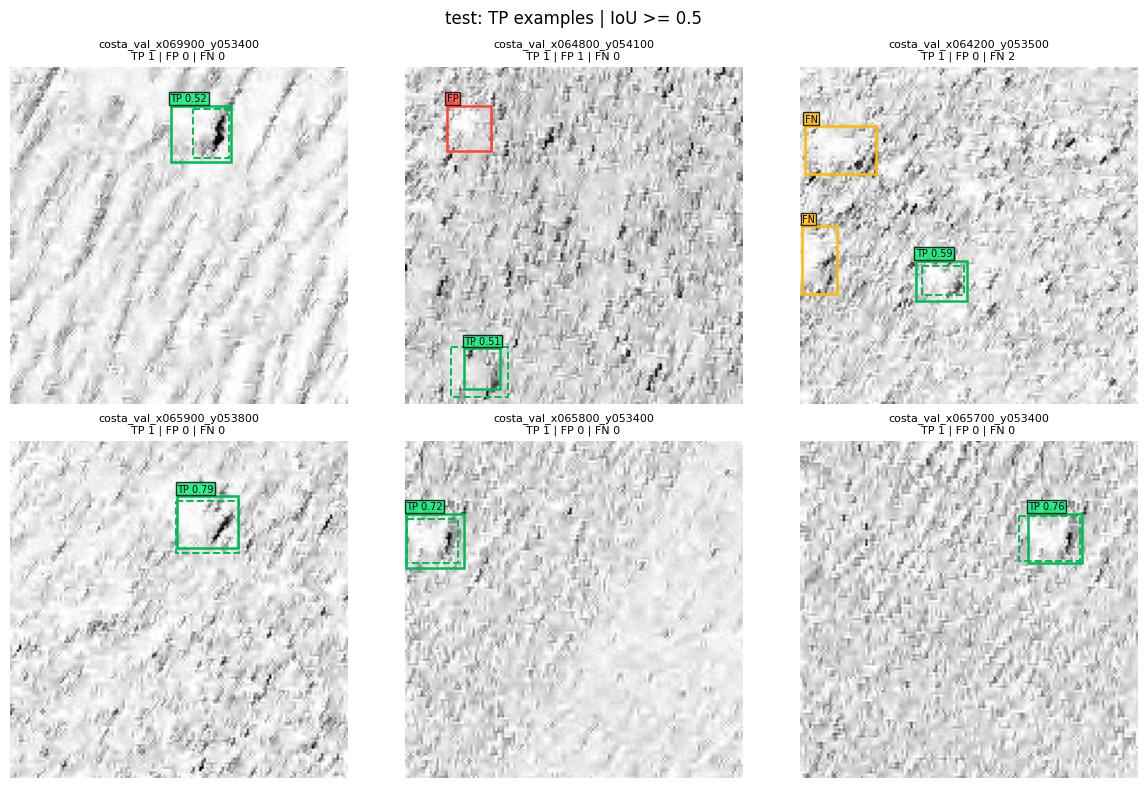

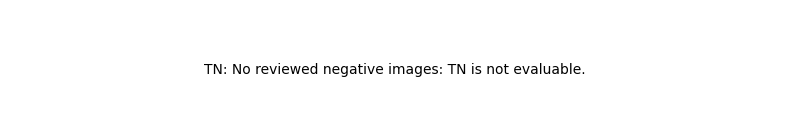

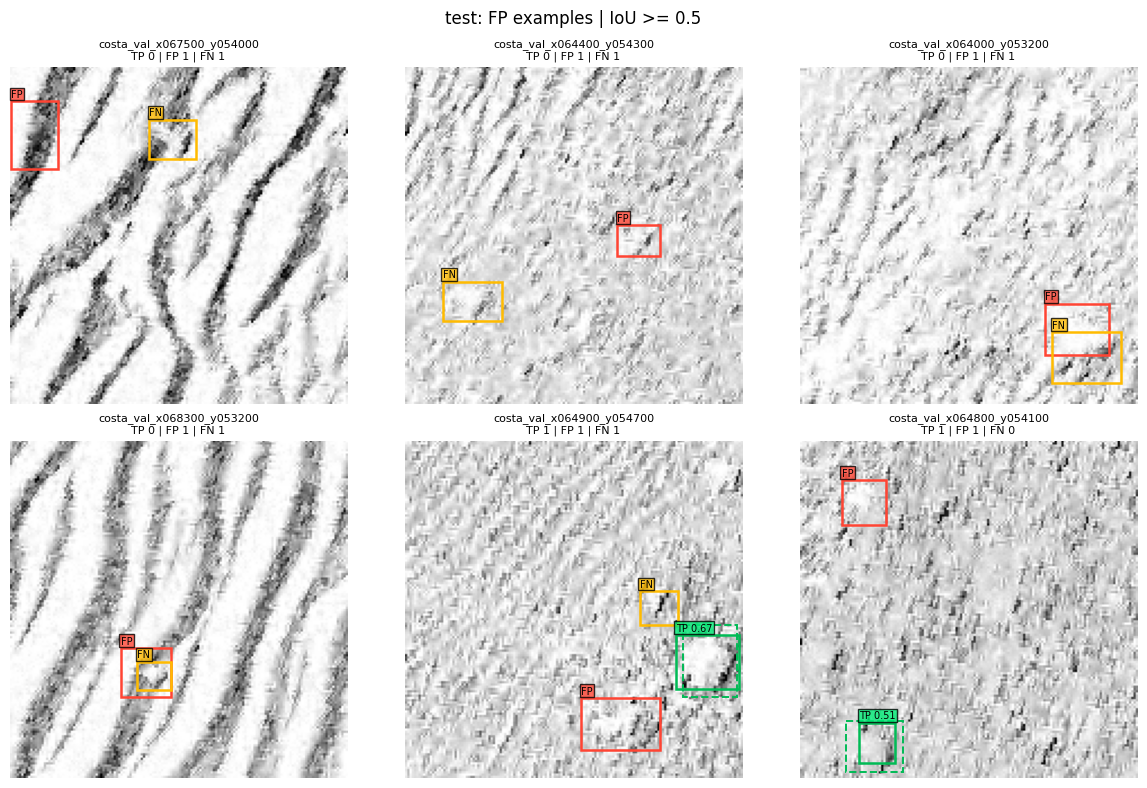

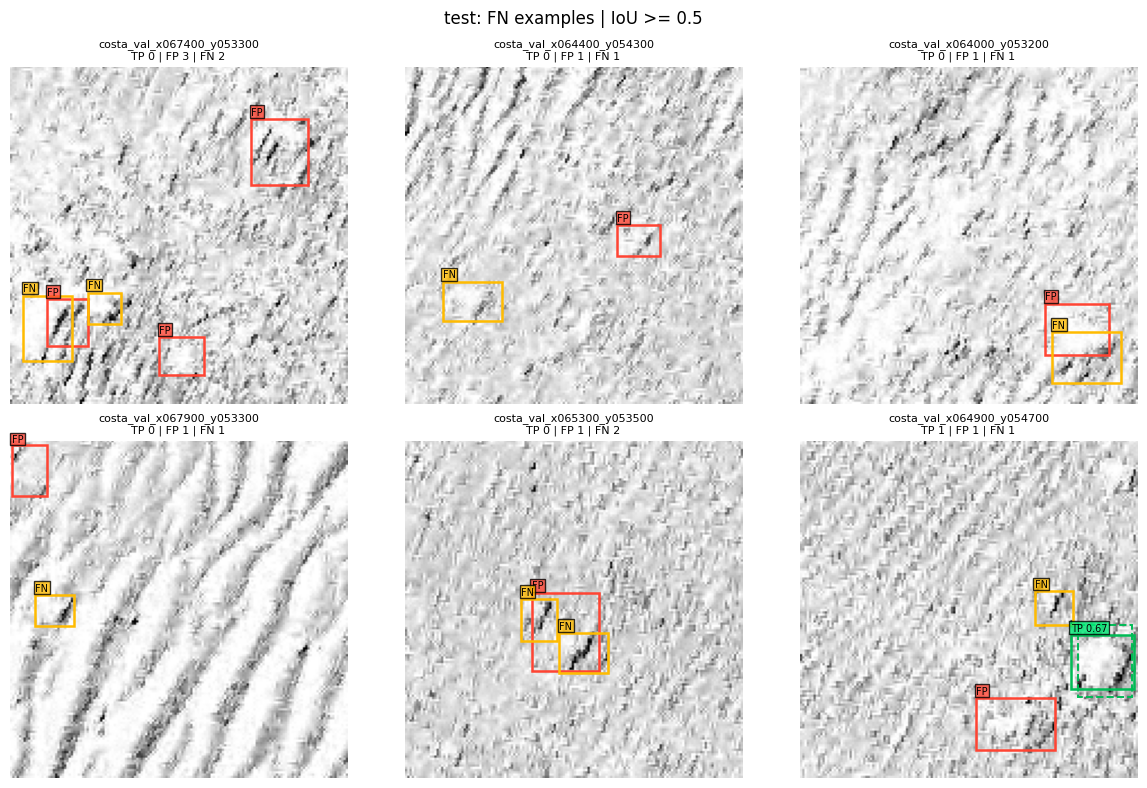

Green solid = matched prediction; green dashed = its GT. Red = unmatched prediction; yellow = unmatched GT.
One image can contain TP, FP and FN together. TN is image-level only.


In [9]:
from matplotlib.patches import Rectangle

def categories(p):
    pairs,fp,fn=match_boxes(p['boxes'],p['ground_truth'],MATCH_IOU)
    names=[]
    if pairs:names.append('TP')
    if fp:names.append('FP')
    if fn:names.append('FN')
    if (p['negative_reviewed'] and not p['ground_truth'] and not p['boxes']
        and p['valid_json'] and not p['hit_token_limit']):names.append('TN')
    return names,pairs,fp,fn

def draw_detection(ax,p):
    with Image.open(p['image']) as im:
        w,h=im.size;ax.imshow(im.convert('RGB'))
    names,pairs,fp,fn=categories(p)
    for i,j,score in pairs:
        g=p['ground_truth'][j];b=p['boxes'][i]
        ax.add_patch(Rectangle((g[0]*w/1000,g[1]*h/1000),(g[2]-g[0])*w/1000,(g[3]-g[1])*h/1000,
                               fill=False,edgecolor='#00bb55',linestyle='--',linewidth=1.4))
        ax.add_patch(Rectangle((b[0]*w/1000,b[1]*h/1000),(b[2]-b[0])*w/1000,(b[3]-b[1])*h/1000,
                               fill=False,edgecolor='#00bb55',linewidth=1.8))
        ax.text(b[0]*w/1000,max(0,b[1]*h/1000-2),f'TP {score:.2f}',color='black',fontsize=7,
                bbox=dict(facecolor='#00ee77',alpha=.8,pad=1))
    for indices,key,color,boxes in [(fp,'FP','#ff4433',p['boxes']),(fn,'FN','#ffbb00',p['ground_truth'])]:
        for j in indices:
            b=boxes[j]
            ax.add_patch(Rectangle((b[0]*w/1000,b[1]*h/1000),(b[2]-b[0])*w/1000,(b[3]-b[1])*h/1000,
                                   fill=False,edgecolor=color,linewidth=1.8))
            ax.text(b[0]*w/1000,max(0,b[1]*h/1000-2),key,color='black',fontsize=7,
                    bbox=dict(facecolor=color,alpha=.8,pad=1))
    note='TN: reviewed background' if 'TN' in names else f'TP {len(pairs)} | FP {len(fp)} | FN {len(fn)}'
    if not p['valid_json']:note+=' | INVALID JSON'
    if p['hit_token_limit']:note+=' | TRUNCATED'
    ax.set_title(p['patch_id']+'\n'+note,fontsize=8);ax.axis('off')

def show_examples(predictions,tag):
    destination=RUN/'examples'/tag;destination.mkdir(parents=True,exist_ok=True)
    chosen={}
    for category in ['TP','TN','FP','FN']:
        candidates=[p for p in predictions if category in categories(p)[0]]

        pool=random.Random(SEED).sample(candidates,min(EXAMPLES_PER_CATEGORY,len(candidates)))
        chosen[category]=[p['patch_id'] for p in pool]
        if not pool:
            explanation=('No reviewed negative images: TN is not evaluable.' if category=='TN' and
                         not any(p['negative_reviewed'] for p in predictions) else 'No examples in this category.')
            fig,ax=plt.subplots(figsize=(8,1.5));ax.axis('off');ax.text(.5,.5,category+': '+explanation,ha='center',va='center',wrap=True)
        else:
            ncols=min(3,len(pool));nrows=math.ceil(len(pool)/ncols)
            fig,axs=plt.subplots(nrows,ncols,figsize=(4*ncols,4*nrows),squeeze=False)
            for ax,p in zip(axs.flat,pool):draw_detection(ax,p)
            for ax in list(axs.flat)[len(pool):]:ax.axis('off')
            fig.suptitle(f'{tag}: {category} examples | IoU >= {MATCH_IOU}',fontsize=12)
        fig.tight_layout();fig.savefig(destination/(category+'.png'),dpi=180,bbox_inches='tight');plt.show()
    save_json('examples/'+tag+'/selected_examples.json',chosen)
    print('Green solid = matched prediction; green dashed = its GT. Red = unmatched prediction; yellow = unmatched GT.')
    print('One image can contain TP, FP and FN together. TN is image-level only.')


show_examples(predictions,SPLIT)


## Saved outputs

Save predictions, metrics, example galleries and run metadata in a new timestamped directory. Check output completeness and confirm that the source adapter is unchanged.


In [10]:
required=[tag+'_predictions.json',tag+'_metrics.json','detection_metrics.csv','selected_manifest.json',
          'predicted_boxes_1000.csv']+[f'examples/{SPLIT}/{k}.png' for k in ['TP','TN','FP','FN']]
assert all((RUN/name).is_file() for name in required)
assert len(predictions)==len(rows)
assert sha256_file(ADAPTER_DIR/'adapter_model.safetensors')==config['adapter_sha256'],'The source adapter has changed.'
save_json('complete.json',{'status':'complete','run':str(RUN),'split':SPLIT,'images':len(rows),
    'partial_run':MAX_IMAGES is not None,'peak_vram_gib':torch.cuda.max_memory_allocated()/2**30,
    'adapter_sha256':config['adapter_sha256'],'model_updated':False,
    'checkpoint_selection':checkpoint_selection,
    'limitations':['Metrics are relative to existing labels, which may omit contacts.',
    'Unreviewed empty-label images excluded; this is a positive-patch subset evaluation.',
    'TP/FP/FN count boxes; no natural box-level TN. Overlapping patches can repeat targets.']})
print('DONE. Saved inference results:',RUN)
if AUTO_DISCONNECT:
    print('Releasing GPU runtime after successful saves.')
    from google.colab import runtime
    runtime.unassign()


DONE. Saved inference results: /content/drive/MyDrive/LLM-fine-tuning/Qwen3-VL-4B-contact/inference_test_20261017T130849_192042Z


## Limitations

Scores are relative to existing labels, which may omit contacts. Positive-only evaluation cannot measure background false-positive rates. These results describe one adapter on the recorded test subset.
